In [3]:
!pip install tensorflow

   ---------------------------------------- 0.0/332.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/332.0 MB ? eta -:--:--
   ---------------------------------------- 0.8/332.0 MB 3.1 MB/s eta 0:01:48
   ---------------------------------------- 1.3/332.0 MB 2.8 MB/s eta 0:01:57
   ---------------------------------------- 2.1/332.0 MB 3.1 MB/s eta 0:01:46
   ---------------------------------------- 2.9/332.0 MB 3.3 MB/s eta 0:01:41
   ---------------------------------------- 3.7/332.0 MB 3.4 MB/s eta 0:01:38
    --------------------------------------- 4.5/332.0 MB 3.5 MB/s eta 0:01:34
    --------------------------------------- 5.0/332.0 MB 3.4 MB/s eta 0:01:38
    --------------------------------------- 5.8/332.0 MB 3.3 MB/s eta 0:01:39
    --------------------------------------- 6.6/332.0 MB 3.4 MB/s eta 0:01:36
    --------------------------------------- 7.3/332.0 MB 3.5 MB/s eta 0:01:34
   - -------------------------------------- 8.4/332.0 MB 3.6 MB/s eta 0:01:31



[notice] A new release of pip is available: 25.2 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
!pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 967.3 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 1.0 MB/s eta 0:00:01
   ----------------------- ---------------- 1.0/1.8 MB 1.1 MB/s eta 0:00:01
   ----------------------------- ---------- 1.3/1.8 MB 1.1 MB/s eta 0:00:01
   ----------------------------------- ---- 1.6/1.8 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 1.3 MB/s  0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 25.2
    Uninstalling pip-25.2:
      Successfully uninstalled pip-25.2
Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tdf
print(tf.__version__)

C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framewo

<IPython.core.display.Javascript object>

2.20.0


In [1]:
# Importing some basic libraries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dataset = pd.read_csv('Churn_Modelling.csv')
dataset.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Divide the dataset into independent and depentend features:(All the independent features and 'Exited' is depentent feature.
# Here RowNumber, CustomerId and Surname has no role.

X = dataset.iloc[:,3:13]
Y = dataset.iloc[:,13]


In [4]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [5]:
Y.head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

### Feature Engineering :


In [6]:
pd.get_dummies(X['Geography'], drop_first = True)   # One hot Encoding 

,Germany,Spain
0,False,False
1,False,True
2,False,False
3,False,False
4,False,True
...,...,...
9995,False,False
9996,False,False
9997,False,False
9998,True,False


In [7]:
geography = pd.get_dummies(X['Geography'], drop_first = True) 
gender = pd.get_dummies(X['Gender'], drop_first = True)

In [8]:
X = X.drop(['Geography', 'Gender'], axis=1)

In [9]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,42,2,0.00,1,1,1,101348.88
1,608,41,1,83807.86,1,0,1,112542.58
2,502,42,8,159660.80,3,1,0,113931.57
3,699,39,1,0.00,2,0,0,93826.63
4,850,43,2,125510.82,1,1,1,79084.10


In [10]:
# Concatenate these variables with dataframe
X = pd.concat([X, geography, gender], axis=1)

In [11]:
### Splitting the dataset into Training set and test set :
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

### Feature Scaling 


In [12]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)


In [13]:
X_train

array([[ 0.16958176, -0.46460796,  0.00666099, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-2.30455945,  0.30102557, -1.37744033, ...,  1.75486502,
        -0.57369368,  0.91601335],
       [-1.19119591, -0.94312892, -1.031415  , ..., -0.5698444 ,
        -0.57369368, -1.09168714],
       ...,
       [ 0.9015152 , -0.36890377,  0.00666099, ..., -0.5698444 ,
        -0.57369368,  0.91601335],
       [-0.62420521, -0.08179119,  1.39076231, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-0.28401079,  0.87525072, -1.37744033, ...,  1.75486502,
        -0.57369368, -1.09168714]])

In [14]:
X_test

array([[-0.55204276, -0.36890377,  1.04473698, ...,  1.75486502,
        -0.57369368, -1.09168714],
       [-1.31490297,  0.10961719, -1.031415  , ..., -0.5698444 ,
        -0.57369368, -1.09168714],
       [ 0.57162971,  0.30102557,  1.04473698, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       ...,
       [-0.74791227, -0.27319958, -1.37744033, ..., -0.5698444 ,
         1.74309049,  0.91601335],
       [-0.00566991, -0.46460796, -0.33936434, ...,  1.75486502,
        -0.57369368,  0.91601335],
       [-0.79945688, -0.84742473,  1.04473698, ...,  1.75486502,
        -0.57369368,  0.91601335]])

In [15]:
X_train.shape

(8000, 11)

### Let's create ANN :


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LeakyReLU, PReLU, ELU, ReLU
from tensorflow.keras.layers import Dropout

C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framewo

In [36]:
# Lets initialize the ANN
classifier = Sequential()

In [37]:
# Adding the input layer
classifier.add(Dense(units=11, activation='relu'))

In [38]:
# Adding the first hidden layer
classifier.add(Dense(units=7, activation='relu'))
classifier.add(Dropout(0.2))

In [39]:
# Adding the second hidden layer
classifier.add(Dense(units=6, activation='relu'))
classifier.add(Dropout(0.3))

In [40]:
# Adding the output layer
classifier.add(Dense(1, activation='sigmoid'))

In [41]:
classifier.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [42]:
# Early Stopping
import tensorflow as tf
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)


In [43]:
model_history = classifier.fit(X_train, y_train, validation_split=0.33, batch_size=10, epochs=1000, callbacks=early_stopping)
# If we take more no. of epochs, after some epochs the accuracy will be stagnant.  

Epoch 1/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7863 - loss: 0.5256 - val_accuracy: 0.7955 - val_loss: 0.4737
Epoch 2/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7955 - loss: 0.4798 - val_accuracy: 0.7955 - val_loss: 0.4510
Epoch 3/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7946 - loss: 0.4566 - val_accuracy: 0.7955 - val_loss: 0.4367
Epoch 4/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7968 - loss: 0.4438 - val_accuracy: 0.7955 - val_loss: 0.4293
Epoch 5/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8093 - loss: 0.4389 - val_accuracy: 0.7955 - val_loss: 0.4220
Epoch 6/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8190 - loss: 0.4257 - val_accuracy: 0.8224 - val_loss: 0.4178
Epoch 7/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8179 - loss: 0.4220 - val_accuracy: 0.8243 - val_loss: 0.4122
Epoch 8/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8210 - loss: 0.4170 - 

In [44]:
model_history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

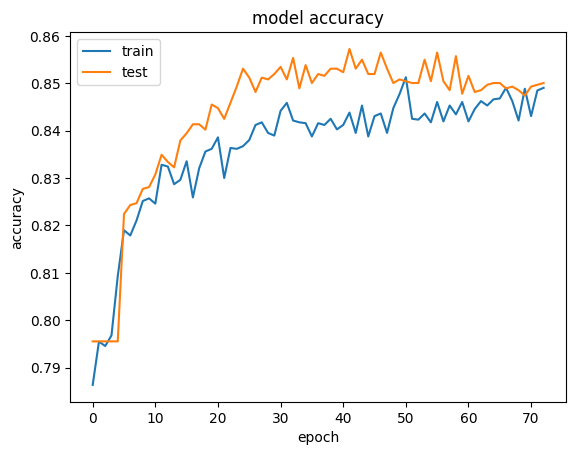

In [45]:
# Summarize history for accuracy
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc = 'upper left')
plt.show()

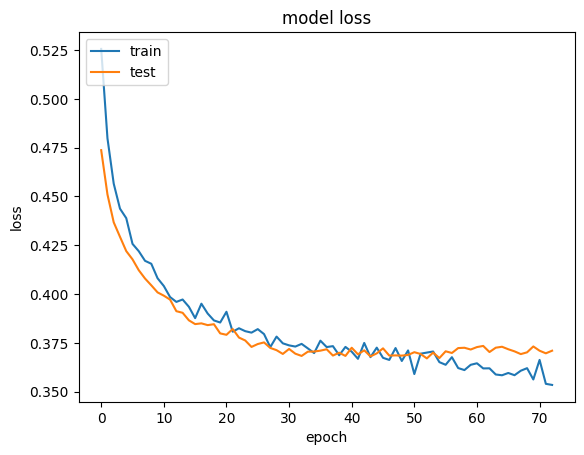

In [46]:
# Summarize history for accuracy
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc = 'upper left')
plt.show()

In [47]:
# Making the predictions and evaluating the model:

# Predicting the Test set results
y_pred = classifier.predict(X_test)
y_pred = (y_pred >= 0.5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [48]:
# Make the confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
cm

array([[1529,   66],
       [ 209,  196]])

In [49]:
# Calculate the accuracy
from sklearn.metrics import accuracy_score
score = accuracy_score(y_pred, y_test)

In [50]:
score


0.8625

In [51]:
# get the weights 
classifier.get_weights()

[array([[ 0.02687027, -0.00393163,  0.10516364, -0.10245025, -0.12380193,
          0.6985772 , -0.12811676, -0.28215942, -0.28950956,  0.10789596,
         -0.00518753],
        [-0.40301827, -0.31997165, -0.6424161 , -0.6558118 ,  0.0233324 ,
         -0.53438115,  0.68173236, -0.2894425 , -0.40927055, -1.1984323 ,
         -0.46429306],
        [-0.1982337 ,  0.10542665, -0.06512588, -0.14640313, -0.05585201,
          0.05287065, -0.01485894,  0.21723454,  0.07931223,  0.01020113,
         -0.14271463],
        [-0.03961097, -0.37754545, -0.6357235 , -0.02242361, -0.6911736 ,
         -0.26993734, -0.29427704, -0.20667362, -0.10954144, -0.04890505,
         -0.40563107],
        [-0.5183717 , -0.184961  , -0.40611818, -0.193725  , -1.446468  ,
         -0.23829435, -0.461932  , -0.48503166, -0.2657545 , -0.5167959 ,
          0.82106495],
        [-0.09981988, -0.16568884,  0.01469424, -0.04542694,  0.05464456,
          0.5412748 ,  0.09424077, -0.0976876 ,  0.17241701,  0.0048844